# Дополнительная лабораторная. Автодифференцирование волны

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "90_wave_autodiff"
OUT.mkdir(exist_ok=True, parents=True)

## Постановка и все четыре функции

Проверяю четыре функции из задания на сетке [−10, 10]² размером 201×201. Тип float64, условие u_xx = u_tt с абсолютным допуском 1e−8.

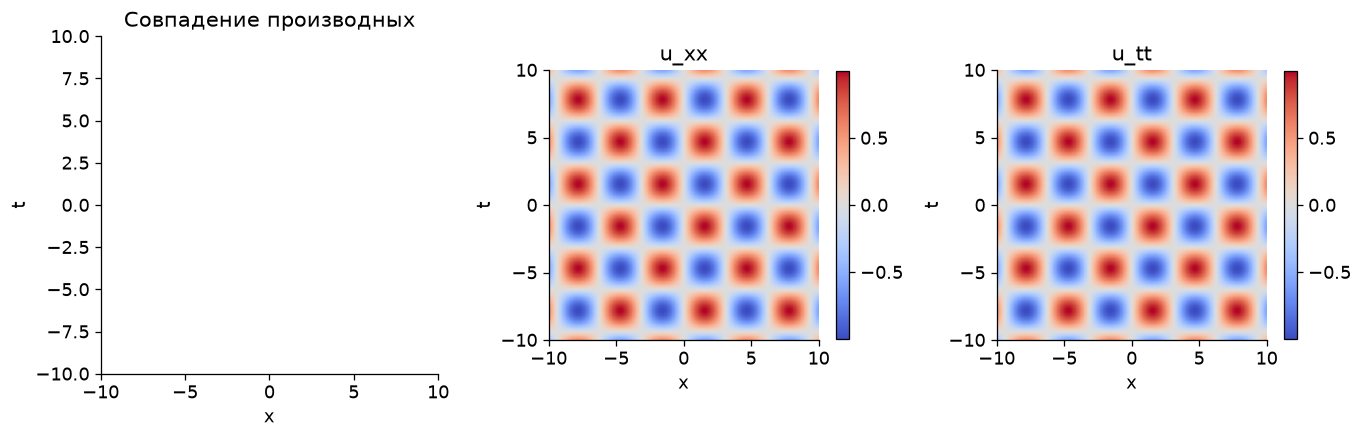

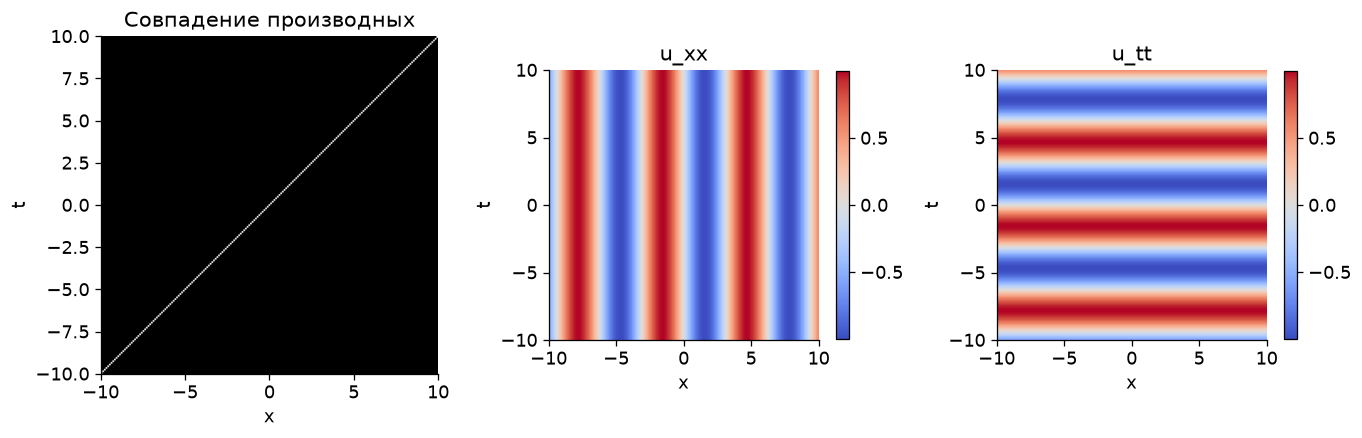

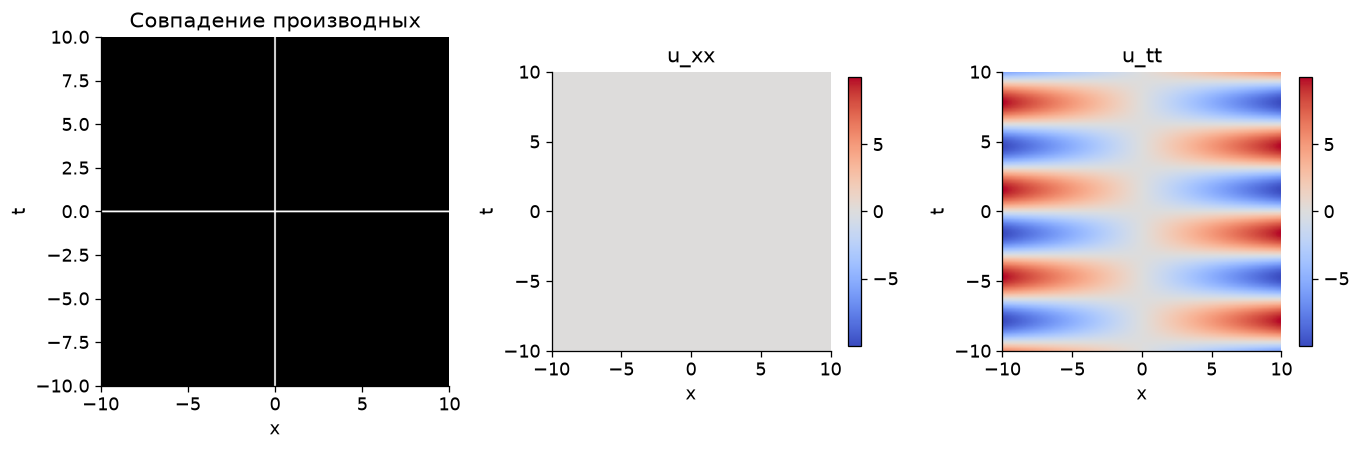

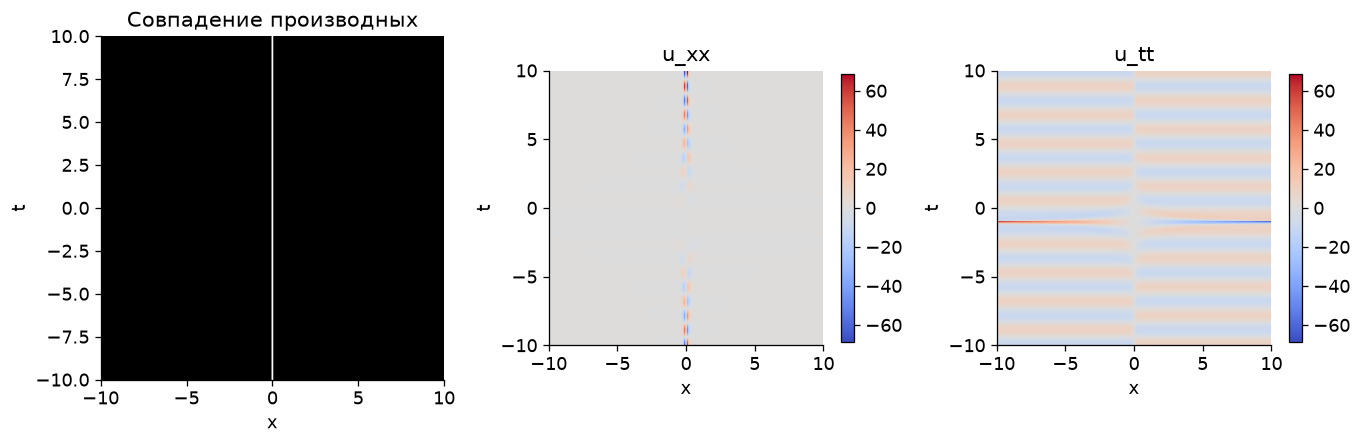

,function_variant,grid_nodes,matching_nodes,matching_fraction,max_abs_residual
0,1,40401,40401,1.00000,0.00000
1,2,40401,201,0.00498,1.99985
2,3,40401,401,0.00993,9.99923
3,4,40401,201,0.00498,61.59475


Векторизация корректна, поскольку каждый элемент u зависит только от своей пары координат. Вторая производная суммы даёт нужные поэлементные производные без смешивания узлов. Для линейной зависимости от x отсутствующая вторая производная заменяется нулём. Белые пиксели обозначают численное выполнение уравнения на сетке; это проверка в узлах с заданным допуском, а не доказательство на всей плоскости.

In [2]:
functions = {
    1: lambda x, t: torch.sin(x) * torch.sin(t),
    2: lambda x, t: torch.sin(x) + torch.sin(t),
    3: lambda x, t: x * torch.sin(t),
    4: lambda x, t: torch.tanh(x * t + x) * torch.sin(3 * t),
}
coords = np.linspace(-10, 10, 201)
X, T = np.meshgrid(coords, coords, indexing="ij")
rows = []


def second_derivative(u, v):
    d = torch.autograd.grad(
        u.sum(), v, create_graph=True, retain_graph=True, allow_unused=True
    )[0]
    if d is None or not d.requires_grad:
        return torch.zeros_like(v)
    dd = torch.autograd.grad(d.sum(), v, retain_graph=True, allow_unused=True)[0]
    return dd if dd is not None else torch.zeros_like(v)


for variant, function in functions.items():
    x = torch.tensor(X.ravel(), dtype=torch.float64, requires_grad=True)
    t = torch.tensor(T.ravel(), dtype=torch.float64, requires_grad=True)
    u = function(x, t)
    uxx = second_derivative(u, x).detach().numpy().reshape(X.shape)
    utt = second_derivative(u, t).detach().numpy().reshape(X.shape)
    residual = uxx - utt
    equal = np.abs(residual) < 1e-8
    if variant == 1:
        assert equal.all()
    if variant == 3:
        assert np.allclose(residual, X * np.sin(T), atol=1e-12)
    rows.append(
        {
            "function_variant": variant,
            "grid_nodes": equal.size,
            "matching_nodes": int(equal.sum()),
            "matching_fraction": equal.mean(),
            "max_abs_residual": np.abs(residual).max(),
        }
    )
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    limit = max(float(np.abs(uxx).max()), float(np.abs(utt).max()), 1e-12)
    for a, image, title in zip(
        ax, [equal, uxx, utt], ["Совпадение производных", "u_xx", "u_tt"]
    ):
        bounds = (
            {"vmin": 0, "vmax": 1}
            if image.dtype == bool
            else {"vmin": -limit, "vmax": limit}
        )
        im = a.imshow(
            image.T,
            origin="lower",
            extent=[-10, 10, -10, 10],
            cmap="gray" if image.dtype == bool else "coolwarm",
            **bounds,
        )
        a.set(title=title, xlabel="x", ylabel="t")
        a.grid(False)
        if image.dtype != bool:
            fig.colorbar(im, ax=a, shrink=0.7)
    showfig(f"wave_variant_{variant}", OUT)
    np.savez_compressed(
        OUT / f"wave_variant_{variant}.npz",
        x=coords,
        t=coords,
        uxx=uxx,
        utt=utt,
        equal=equal,
    )
    positions = np.argwhere(equal)
    pd.DataFrame({"x": coords[positions[:, 0]], "t": coords[positions[:, 1]]}).to_csv(
        OUT / f"matching_coordinates_{variant}.csv", index=False
    )
df = table(rows, OUT)
note(
    "Векторизация корректна, поскольку каждый элемент u зависит только от своей пары координат. Вторая производная суммы даёт нужные поэлементные производные без смешивания узлов. Для линейной зависимости от x отсутствующая вторая производная заменяется нулём. Белые пиксели обозначают численное выполнение уравнения на сетке; это проверка в узлах с заданным допуском, а не доказательство на всей плоскости."
)

## Аналитическая проверка

Для функций 1–3 выписываю условия равенства производных. Для функции 4 сравниваю аналитический остаток с autograd.

In [3]:
# u1_xx = u1_tt = -sin(x)sin(t).
# u2_xx - u2_tt = -sin(x) + sin(t).
# u3_xx - u3_tt = x*sin(t).
x = torch.tensor(X.ravel(), dtype=torch.float64, requires_grad=True)
t = torch.tensor(T.ravel(), dtype=torch.float64, requires_grad=True)
u = functions[4](x, t)
numerical = (second_derivative(u, x) - second_derivative(u, t)).detach().numpy()
s = X * (T + 1)
sech2 = 1 - np.tanh(s) ** 2
analytical = (
    -2 * (T + 1) ** 2 * np.tanh(s) * sech2 * np.sin(3 * T)
    + 2 * X**2 * np.tanh(s) * sech2 * np.sin(3 * T)
    - 6 * X * sech2 * np.cos(3 * T)
    + 9 * np.tanh(s) * np.sin(3 * T)
).ravel()
print("Max error analytic/autograd variant4:", np.max(abs(numerical - analytical)))
assert np.allclose(numerical, analytical, atol=1e-10)
note(
    "Функция 1 решает уравнение всюду. Для 2 равенство выполняется при sin(x)=sin(t), то есть x=t+2πk или x=π−t+2πk. Для 3 условие x·sin(t)=0: x=0 либо t=kπ. Для 4 условие задаётся нулём выведенного аналитического остатка; координаты подходящих узлов сохранены в CSV. При больших |x(t+1)| насыщение tanh требует осторожности с абсолютным допуском."
)

Max error analytic/autograd variant4: 5.3290705182007514e-14


Функция 1 решает уравнение всюду. Для 2 равенство выполняется при sin(x)=sin(t), то есть x=t+2πk или x=π−t+2πk. Для 3 условие x·sin(t)=0: x=0 либо t=kπ. Для 4 условие задаётся нулём выведенного аналитического остатка; координаты подходящих узлов сохранены в CSV. При больших |x(t+1)| насыщение tanh требует осторожности с абсолютным допуском.